# Benchmark: CXR-only vs CXR+EHR — 8 nhóm bệnh (`dx_*`)

Đo **giá trị gia tăng của EHR** so với chỉ dùng ảnh CXR, dùng **mô hình cơ bản, KHÔNG xử lý mất cân bằng** (không class_weight/SMOTE, ngưỡng cố định **0.5**).

- **Dữ liệu:** `fusion_dataset_hybrid.parquet` (nội dung y hệt `_full.csv`, nhanh hơn nhiều). Image-level.
- **Split chính thức MIMIC:** fit trên `train`, đánh giá trên `test` (patient-safe).
- **Mô hình:** DecisionTree, LogisticRegression, RandomForest.
- **2 nhóm feature:** `CXR` = 768 embedding RAD-DINO; `CXR+EHR` = 768 + toàn bộ EHR (labs, vitals, vi sinh, cờ nhị phân, tuổi/giới).
- **6 chỉ số:** accuracy, precision, recall, f1, f2, auprc.
- **CHỈ CẦN CPU** — không GPU. (RandomForest là phần lâu nhất.)

> ⚠️ Nhãn `dx_*` là **per-patient "từng-bị"** (gom mọi lần nhập viện) → mô hình học *tiền sử bệnh*, không phải "ảnh này thể hiện bệnh". Ảnh chụp lúc khỏe vẫn mang nhãn dương. Đây là giới hạn thiết kế.

## 0. (Colab) Mount Drive + tự tìm thư mục chứa dataset

In [1]:
# Nếu chạy Colab:
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception as e:
    print('không phải Colab / đã mount:', e)

import os
# chỉnh danh sách này nếu thư mục của bạn khác
CANDIDATES = [
    # '/content/drive/MyDrive/MIMIC_CXR/planB_firstobs_out',
    '/content/drive/MyDrive/MIMIC_CXR/planB_out',
]
def _has_data(d):
    return os.path.exists(os.path.join(d,'fusion_dataset_hybrid.parquet')) or \
           os.path.exists(os.path.join(d,'fusion_dataset_hybrid_full.csv'))
OUT_DIR = next((d for d in CANDIDATES if _has_data(d)), CANDIDATES[0])
print('OUT_DIR =', OUT_DIR, '| có dữ liệu:', _has_data(OUT_DIR))
assert _has_data(OUT_DIR), 'Không thấy fusion_dataset_hybrid.parquet/_full.csv — sửa OUT_DIR cho đúng.'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OUT_DIR = /content/drive/MyDrive/MIMIC_CXR/planB_out | có dữ liệu: True


In [ ]:
# import pandas as pd, os
# FULL_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out'            # fusion FULL đã cập nhật
# FO_DIR   = '/content/drive/MyDrive/MIMIC_CXR/planB_firstobs_out'   # ghi FirstObs mới

# full = pd.read_parquet(os.path.join(FULL_DIR,'fusion_dataset_hybrid.parquet'))
# # kiểm tra Full đã cập nhật đủ chưa
# ok = {'diabetes':'diabetes' in full.columns,
#       'time':all(c in full.columns for c in ['study_dt','admittime','ed_intime','encounter_time']),
#       'no_admin':not any(c in full.columns for c in ['admission_type','insurance','race','marital_status'])}
# print("full:", full.shape, "| union bệnh nhân:", full.subject_id.nunique(), "|", ok)
# assert all(ok.values()), "Full chưa cập nhật đủ (union/diabetes/time/admin) — cập nhật Full trước đã!"

# # first observation = STUDY sớm nhất mỗi bệnh nhân (giữ mọi ảnh của study đó)
# order = full.sort_values(['subject_id','study_dt','study_id'])
# first_study = order.groupby('subject_id')['study_id'].first()          # study_id đầu mỗi BN
# fo = full[full['subject_id'].map(first_study).eq(full['study_id'])].copy()

# os.makedirs(FO_DIR, exist_ok=True)
# fo.to_parquet(os.path.join(FO_DIR,'fusion_dataset_hybrid.parquet'), index=False)
# fo[[c for c in fo.columns if not c.startswith('img_')]].to_csv(
#     os.path.join(FO_DIR,'fusion_dataset_hybrid.csv'), index=False)
# # bản CSV full kèm 768 ảnh (nếu cần)
# fo.to_csv(os.path.join(FO_DIR,'fusion_dataset_hybrid_full.csv'), index=False)
# print("FirstObs mới:", fo.shape, "| bệnh nhân:", fo.subject_id.nunique(),
#       "| img:", sum(c.startswith('img_') for c in fo.columns),
#       "| diabetes:", 'diabetes' in fo.columns, "| encounter_time:", 'encounter_time' in fo.columns)


full: (231684, 860) | union bệnh nhân: 26043 | {'diabetes': True, 'time': True, 'no_admin': True}
FirstObs mới: (47151, 860) | bệnh nhân: 26043 | img: 768 | diabetes: True | encounter_time: True


In [ ]:
# fp = pd.read_parquet(os.path.join(FO_DIR,'fusion_dataset_hybrid_fullmicro.parquet'))
# print("parquet FO:", fp.shape, "| img:", sum(c.startswith('img_') for c in fp.columns),
#       "| org/spec:", sum(c.startswith(('org_','spec_')) for c in fp.columns))
# fp.to_csv(os.path.join(FO_DIR,'fusion_dataset_hybrid_fullmicro.csv'), index=False)
# print("CSV FO (kèm ảnh):", fp.shape, "| img:", sum(c.startswith('img_') for c in fp.columns))


parquet FO: (47151, 1537) | img: 768 | org/spec: 712
CSV FO (kèm ảnh): (47151, 1537) | img: 768


In [ ]:
# df = pd.read_csv(os.path.join(FO_DIR,'fusion_dataset_hybrid_fullmicro.csv'))
# df.shape


(47151, 1537)

In [ ]:
# import pandas as pd, glob, os
# for p in sorted(glob.glob(os.path.join(FO_DIR,'fusion_dataset_*'))):
#     cols = (pd.read_parquet(p).columns if p.endswith('.parquet')
#             else pd.read_csv(p, nrows=0).columns)
#     print(f"{os.path.basename(p):40}",
#           "| diabetes:", 'diabetes' in cols,
#           "| enc_time:", 'encounter_time' in cols,
#           "| admin?:", any(c in cols for c in ['admission_type','insurance','race','marital_status']),
#           "| rows:", (pd.read_parquet(p).shape[0] if p.endswith('.parquet') else '-'))


fusion_dataset_encounter.csv             | diabetes: False | enc_time: False | admin?: True | rows: -
fusion_dataset_encounter.parquet         | diabetes: False | enc_time: False | admin?: True | rows: 41341
fusion_dataset_firstadm.csv              | diabetes: False | enc_time: False | admin?: True | rows: -
fusion_dataset_firstadm.parquet          | diabetes: False | enc_time: False | admin?: True | rows: 41341
fusion_dataset_hybrid.csv                | diabetes: True | enc_time: True | admin?: False | rows: -
fusion_dataset_hybrid.parquet            | diabetes: True | enc_time: True | admin?: False | rows: 47151
fusion_dataset_hybrid_full.csv           | diabetes: True | enc_time: True | admin?: False | rows: -
fusion_dataset_hybrid_fullmicro.csv      | diabetes: False | enc_time: False | admin?: True | rows: -
fusion_dataset_hybrid_fullmicro.parquet  | diabetes: False | enc_time: False | admin?: True | rows: 41341


In [ ]:
# for name in ['encounter','firstadm','hybrid_fullmicro']:
#     fp = os.path.join(FULL_DIR, f'fusion_dataset_{name}.parquet')
#     if not os.path.exists(fp): print("bỏ qua (Full không có):", name); continue
#     fu = pd.read_parquet(fp)
#     if 'study_dt' not in fu.columns:
#         print("bỏ qua (Full", name, "cũng chưa có study_dt → cần cập nhật Full trước)"); continue
#     fs = fu.sort_values(['subject_id','study_dt','study_id']).groupby('subject_id')['study_id'].first()
#     sub = fu[fu['subject_id'].map(fs).eq(fu['study_id'])].copy()
#     sub.to_parquet(os.path.join(FO_DIR, f'fusion_dataset_{name}.parquet'), index=False)
#     sub[[c for c in sub.columns if not c.startswith('img_')]].to_csv(
#         os.path.join(FO_DIR, f'fusion_dataset_{name}.csv'), index=False)
#     print(name, "->", sub.shape, "| diabetes:", 'diabetes' in sub.columns)


bỏ qua (Full không có): encounter
bỏ qua (Full không có): firstadm
hybrid_fullmicro -> (47151, 1537) | diabetes: True


## 1. Load + preprocess + split

In [2]:
import pandas as pd, numpy as np, os
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# đọc parquet (nhanh/nhẹ hơn CSV 1.9GB, nội dung y hệt _full.csv); fallback CSV
pq = os.path.join(OUT_DIR,'fusion_dataset_hybrid.parquet')
df = pd.read_parquet(pq) if os.path.exists(pq) else pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'))
print("shape:", df.shape); print(df.split.value_counts())

GROUPS = ['pneumonia','bronchitis','tuberculosis','arthritis','fracture','scoliosis','lung_cancer','lung_infection']
IMG = [f'img_{i}' for i in range(768)]
DROP_EXACT = {'dicom_id','subject_id','study_id','hadm_id','stay_id','first_hadm_id',
              'first_admittime','first_icd10_codes','study_dt','admittime','ed_intime',
              'encounter_time','split','view','disease_group','chiefcomplaint'}
EHR = [c for c in df.columns if not c.startswith(('img_','y_','dx_')) and c not in DROP_EXACT]
if 'gender' in EHR: df['gender'] = df['gender'].map({'M':1,'F':0})   # encode
print("IMG:", len(IMG), "| EHR:", len(EHR)); print("EHR:", EHR)

# tr = (df.split=='train').values; te = (df.split=='test').values
# print("train:", tr.sum(), "| test:", te.sum())
# print("n_pos_test mỗi bệnh:", {g:int(df.loc[te,f'dx_{g}'].sum()) for g in GROUPS})

TEST_FRAC = 0.2                       # 8:2 ; đổi 0.3 cho 7:3
uniq = df.subject_id.unique()
rng = np.random.default_rng(0); rng.shuffle(uniq)
cut = int((1-TEST_FRAC)*len(uniq))
tr_p = set(uniq[:cut])
tr = df.subject_id.isin(tr_p).values
te = ~tr
assert not (set(df.loc[tr,'subject_id']) & set(df.loc[te,'subject_id']))   # 0 rò rỉ
print("train:", tr.sum(), "| test:", te.sum())
print("n_pos_test:", {g:int(df.loc[te,f'dx_{g}'].sum()) for g in GROUPS})

def prep(cols):                                        # impute(median)+scale, FIT TRÊN TRAIN
    X  = df[cols].apply(pd.to_numeric, errors='coerce').to_numpy('float32')
    Xi = SimpleImputer(strategy='median').fit(X[tr]).transform(X)
    return StandardScaler().fit(Xi[tr]).transform(Xi).astype('float32')

FEATSETS = {'CXR': IMG, 'CXR+EHR': IMG+EHR}
Xcache = {n: prep(c) for n,c in FEATSETS.items()}
print("prep xong:", {k:v.shape for k,v in Xcache.items()})

shape: (231684, 860)
split
train       225392
test          4513
validate      1779
Name: count, dtype: int64
IMG: 768 | EHR: 58
EHR: ['age', 'gender', 'lab_hemoglobin', 'lab_wbc', 'lab_rbc', 'lab_platelet', 'lab_creatinine', 'lab_sodium', 'lab_potassium', 'lab_glucose', 'lab_bun', 'lab_chloride', 'vital_heart_rate', 'vital_spo2', 'vital_temperature', 'vital_resprate', 'vital_sbp', 'vital_dbp', 'ed_cough', 'smoke', 'cough', 'diabetes', 'n_positive_cultures', 'org_CANCELLED', 'org_CITROBACTER_FREUNDII_COMPLEX', 'org_ENTEROBACTER_AEROGENES', 'org_ENTEROBACTER_CLOACAE', 'org_ENTEROBACTER_CLOACAE_COMPLEX', 'org_ENTEROCOCCUS_FAECALIS', 'org_ENTEROCOCCUS_FAECIUM', 'org_ENTEROCOCCUS_SP.', 'org_ESCHERICHIA_COLI', 'org_KLEBSIELLA_OXYTOCA', 'org_KLEBSIELLA_PNEUMONIAE', 'org_MIXED_BACTERIAL_FLORA', 'org_MORGANELLA_MORGANII', 'org_PROTEUS_MIRABILIS', 'org_PSEUDOMONAS_AERUGINOSA', 'org_SERRATIA_MARCESCENS', 'org_STAPH_AUREUS_COAG_+', 'org_STAPHYLOCOCCUS_EPIDERMIDIS', 'org_STAPHYLOCOCCUS,_COAGULASE_

## 2. Train 3 mô hình × 2 nhóm feature × 8 bệnh → bảng metrics

`TRAIN_CAP=None` = dùng toàn bộ train. Muốn chạy thử nhanh, đặt `TRAIN_CAP=60000`.
48 lần fit; **RandomForest** lâu nhất trên CPU.

In [3]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, average_precision_score)

TRAIN_CAP = None    # None=full; đặt số (vd 60000) để chạy thử nhanh
MODELS = {
    'DecisionTree': lambda: DecisionTreeClassifier(random_state=0),
    'LogReg':       lambda: LogisticRegression(max_iter=1000, n_jobs=-1),
    'RandomForest': lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0),
}

tr_idx = np.where(tr)[0]; te_idx = np.where(te)[0]
if TRAIN_CAP and len(tr_idx)>TRAIN_CAP:
    tr_idx = np.random.default_rng(0).choice(tr_idx, TRAIN_CAP, replace=False)

rows=[]
for fname, cols in FEATSETS.items():
    Xtr, Xte = Xcache[fname][tr_idx], Xcache[fname][te_idx]
    for mname, mk in MODELS.items():
        for g in GROUPS:
            y = df[f'dx_{g}'].values.astype(int); ytr, yte = y[tr_idx], y[te_idx]
            t0=time.time(); clf = mk().fit(Xtr, ytr)
            proba = clf.predict_proba(Xte)[:,1]; pred = (proba>=0.5).astype(int)
            rows.append(dict(model=mname, featset=fname, disease=g,
                accuracy=accuracy_score(yte,pred),
                precision=precision_score(yte,pred,zero_division=0),
                recall=recall_score(yte,pred,zero_division=0),
                f1=f1_score(yte,pred,zero_division=0),
                f2=fbeta_score(yte,pred,beta=2,zero_division=0),
                auprc=average_precision_score(yte,proba),
                prevalence=float(yte.mean()), n_pos_test=int(yte.sum())))
            print(f"[{fname:8}] {mname:12} {g:15} f1={rows[-1]['f1']:.3f} auprc={rows[-1]['auprc']:.3f} ({time.time()-t0:.0f}s)")

results = pd.DataFrame(rows)
results.to_csv(os.path.join(OUT_DIR,'benchmark_cxr_vs_ehr.csv'), index=False)
print("\nlưu benchmark_cxr_vs_ehr.csv | dòng:", len(results), "(kỳ vọng 48)")
results.head(12)

[CXR     ] DecisionTree pneumonia       f1=0.576 auprc=0.733 (96s)
[CXR     ] DecisionTree bronchitis      f1=0.277 auprc=0.220 (353s)
[CXR     ] DecisionTree tuberculosis    f1=0.042 auprc=0.071 (647s)
[CXR     ] DecisionTree arthritis       f1=0.306 auprc=0.217 (170s)
[CXR     ] DecisionTree fracture        f1=0.479 auprc=0.465 (115s)
[CXR     ] DecisionTree scoliosis       f1=0.000 auprc=0.018 (685s)
[CXR     ] DecisionTree lung_cancer     f1=0.284 auprc=0.246 (323s)
[CXR     ] DecisionTree lung_infection  f1=0.080 auprc=0.032 (731s)
[CXR     ] LogReg       pneumonia       f1=0.738 auprc=0.809 (4s)
[CXR     ] LogReg       bronchitis      f1=0.128 auprc=0.435 (4s)
[CXR     ] LogReg       tuberculosis    f1=0.000 auprc=0.144 (3s)
[CXR     ] LogReg       arthritis       f1=0.148 auprc=0.303 (4s)
[CXR     ] LogReg       fracture        f1=0.418 auprc=0.552 (4s)
[CXR     ] LogReg       scoliosis       f1=0.000 auprc=0.058 (3s)
[CXR     ] LogReg       lung_cancer     f1=0.336 auprc=0.507 

,model,featset,disease,accuracy,precision,recall,f1,f2,auprc,prevalence,n_pos_test
0,DecisionTree,CXR,pneumonia,0.461340,0.710000,0.484642,0.576065,0.517493,0.733271,0.755155,293
1,DecisionTree,CXR,bronchitis,0.757732,0.315789,0.246575,0.276923,0.257880,0.219618,0.188144,73
2,DecisionTree,CXR,tuberculosis,0.881443,0.050000,0.035714,0.041667,0.037879,0.071373,0.072165,28
3,DecisionTree,CXR,arthritis,0.742268,0.297297,0.314286,0.305556,0.310734,0.217148,0.180412,70
4,DecisionTree,CXR,fracture,0.590206,0.517730,0.445122,0.478689,0.457967,0.464989,0.422680,164
5,DecisionTree,CXR,scoliosis,0.940722,0.000000,0.000000,0.000000,0.000000,0.018041,0.018041,7
6,DecisionTree,CXR,lung_cancer,0.701031,0.306667,0.264368,0.283951,0.271868,0.246021,0.224227,87
7,DecisionTree,CXR,lung_infection,0.940722,0.071429,0.090909,0.080000,0.086207,0.032267,0.028351,11
8,LogReg,CXR,pneumonia,0.626289,0.784615,0.696246,0.737794,0.712291,0.808801,0.755155,293
9,LogReg,CXR,bronchitis,0.824742,1.000000,0.068493,0.128205,0.084175,0.435111,0.188144,73


In [5]:
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, average_precision_score)
import time, os, pandas as pd

def build_xgb():                              # mặc định, KHÔNG scale_pos_weight (không xử lý imbalance)
    return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                         subsample=0.85, colsample_bytree=0.85, tree_method='hist',
                         eval_metric='logloss', n_jobs=-1, random_state=0)

xgb_rows=[]
for fname, cols in FEATSETS.items():
    Xtr, Xte = Xcache[fname][tr_idx], Xcache[fname][te_idx]
    for g in GROUPS:
        y = df[f'dx_{g}'].values.astype(int); ytr, yte = y[tr_idx], y[te_idx]
        t0=time.time(); clf = build_xgb().fit(Xtr, ytr)
        proba = clf.predict_proba(Xte)[:,1]; pred=(proba>=0.5).astype(int)
        xgb_rows.append(dict(model='XGBoost', featset=fname, disease=g,
            accuracy=accuracy_score(yte,pred),
            precision=precision_score(yte,pred,zero_division=0),
            recall=recall_score(yte,pred,zero_division=0),
            f1=f1_score(yte,pred,zero_division=0),
            f2=fbeta_score(yte,pred,beta=2,zero_division=0),
            auprc=average_precision_score(yte,proba),
            prevalence=float(yte.mean()), n_pos_test=int(yte.sum())))
        print(f"[{fname:8}] XGBoost {g:15} f1={xgb_rows[-1]['f1']:.3f} auprc={xgb_rows[-1]['auprc']:.3f} ({time.time()-t0:.0f}s)")

# gộp vào benchmark_cxr_vs_ehr.csv (thay dòng XGBoost cũ nếu chạy lại)
p = os.path.join(OUT_DIR,'benchmark_cxr_vs_ehr.csv')
old = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame()
if len(old): old = old[old.model!='XGBoost']
results = pd.concat([old, pd.DataFrame(xgb_rows)], ignore_index=True)
results.to_csv(p, index=False)
print("cập nhật xong | tổng dòng:", len(results))


[CXR     ] XGBoost pneumonia       f1=0.736 auprc=0.816 (44s)
[CXR     ] XGBoost bronchitis      f1=0.053 auprc=0.474 (43s)
[CXR     ] XGBoost tuberculosis    f1=0.000 auprc=0.128 (41s)
[CXR     ] XGBoost arthritis       f1=0.082 auprc=0.346 (41s)
[CXR     ] XGBoost fracture        f1=0.397 auprc=0.549 (41s)
[CXR     ] XGBoost scoliosis       f1=0.000 auprc=0.107 (40s)
[CXR     ] XGBoost lung_cancer     f1=0.280 auprc=0.504 (42s)
[CXR     ] XGBoost lung_infection  f1=0.000 auprc=0.078 (40s)
[CXR+EHR ] XGBoost pneumonia       f1=0.847 auprc=0.902 (43s)
[CXR+EHR ] XGBoost bronchitis      f1=0.161 auprc=0.441 (43s)
[CXR+EHR ] XGBoost tuberculosis    f1=0.000 auprc=0.121 (42s)
[CXR+EHR ] XGBoost arthritis       f1=0.127 auprc=0.412 (43s)
[CXR+EHR ] XGBoost fracture        f1=0.383 auprc=0.586 (43s)
[CXR+EHR ] XGBoost scoliosis       f1=0.000 auprc=0.132 (42s)
[CXR+EHR ] XGBoost lung_cancer     f1=0.365 auprc=0.574 (42s)
[CXR+EHR ] XGBoost lung_infection  f1=0.000 auprc=0.209 (42s)
cập nhật

In [7]:
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, average_precision_score)
import time, os, pandas as pd

def build_lgbm():                              # mặc định, KHÔNG xử lý imbalance
    return LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                          subsample=0.85, colsample_bytree=0.85,
                          n_jobs=-1, random_state=0, verbose=-1)

lgb_rows=[]
for fname, cols in FEATSETS.items():
    Xtr, Xte = Xcache[fname][tr_idx], Xcache[fname][te_idx]
    for g in GROUPS:
        y = df[f'dx_{g}'].values.astype(int); ytr, yte = y[tr_idx], y[te_idx]
        t0=time.time(); clf = build_lgbm().fit(Xtr, ytr)
        proba = clf.predict_proba(Xte)[:,1]; pred=(proba>=0.5).astype(int)
        lgb_rows.append(dict(model='LightGBM', featset=fname, disease=g,
            accuracy=accuracy_score(yte,pred),
            precision=precision_score(yte,pred,zero_division=0),
            recall=recall_score(yte,pred,zero_division=0),
            f1=f1_score(yte,pred,zero_division=0),
            f2=fbeta_score(yte,pred,beta=2,zero_division=0),
            auprc=average_precision_score(yte,proba),
            prevalence=float(yte.mean()), n_pos_test=int(yte.sum())))
        print(f"[{fname:8}] LightGBM {g:15} f1={lgb_rows[-1]['f1']:.3f} auprc={lgb_rows[-1]['auprc']:.3f} ({time.time()-t0:.0f}s)")

# gộp vào benchmark_cxr_vs_ehr.csv (thay dòng LightGBM cũ nếu chạy lại)
p = os.path.join(OUT_DIR,'benchmark_cxr_vs_ehr.csv')
old = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame()
if len(old): old = old[old.model!='LightGBM']
results = pd.concat([old, pd.DataFrame(lgb_rows)], ignore_index=True)
results.to_csv(p, index=False)
print("cập nhật xong | tổng dòng:", len(results))


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CXR     ] LightGBM pneumonia       f1=0.742 auprc=0.825 (29s)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CXR     ] LightGBM bronchitis      f1=0.104 auprc=0.414 (28s)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CXR+EHR ] LightGBM scoliosis       f1=0.000 auprc=0.204 (32s)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CXR+EHR ] LightGBM lung_cancer     f1=0.383 auprc=0.556 (30s)
[CXR+EHR ] LightGBM lung_infection  f1=0.000 auprc=0.174 (31s)
cập nhật xong | tổng dòng: 80


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 3. Heatmap so 2 nhóm (CXR-only, CXR+EHR, và Δ)

Δ = (CXR+EHR) − CXR: ô **đỏ** = thêm EHR cải thiện, ô **xanh** = EHR làm giảm.

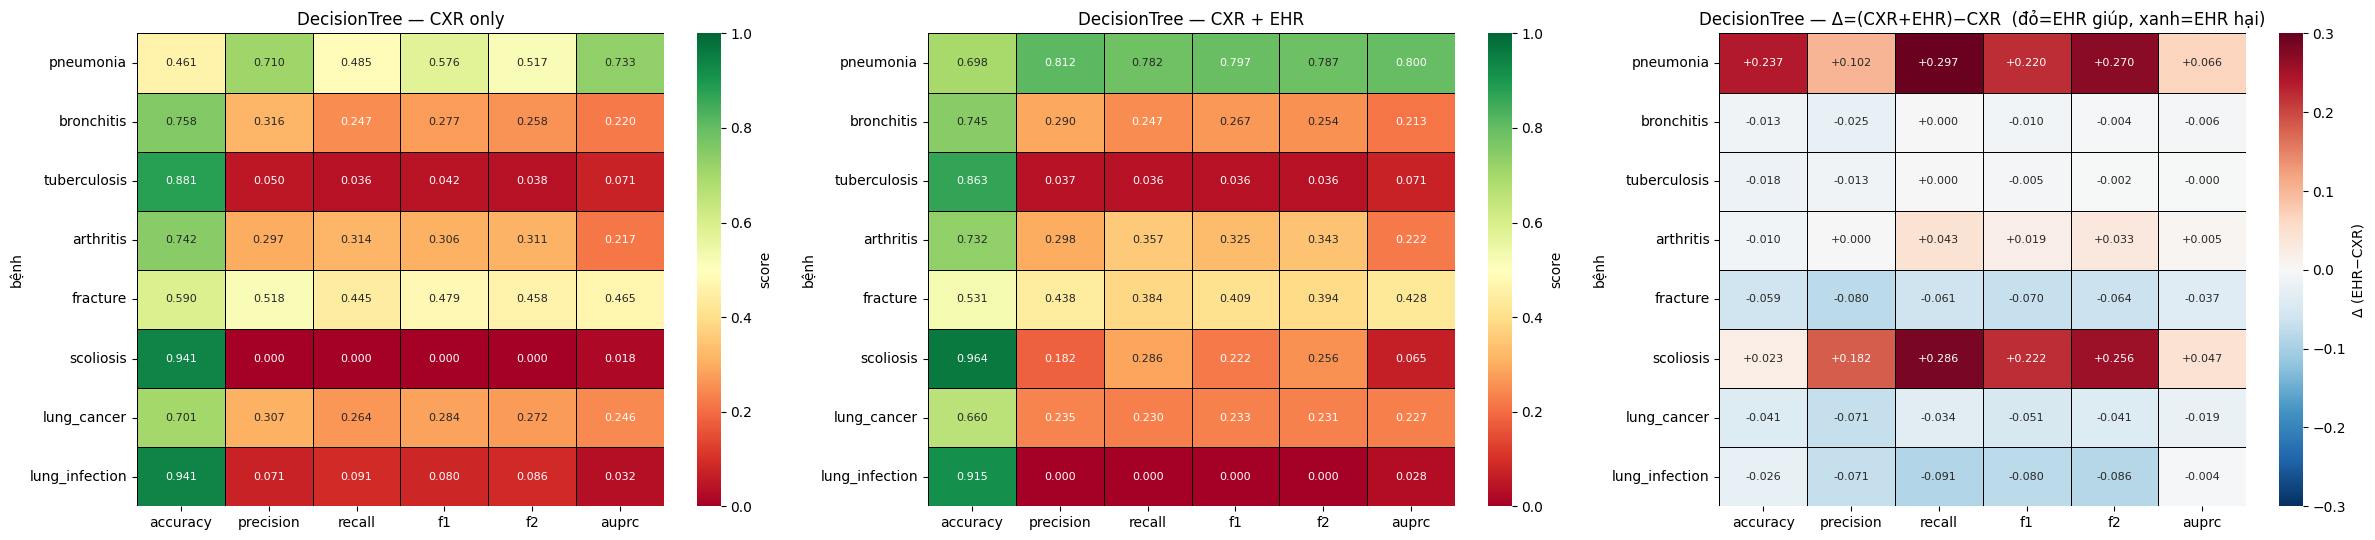

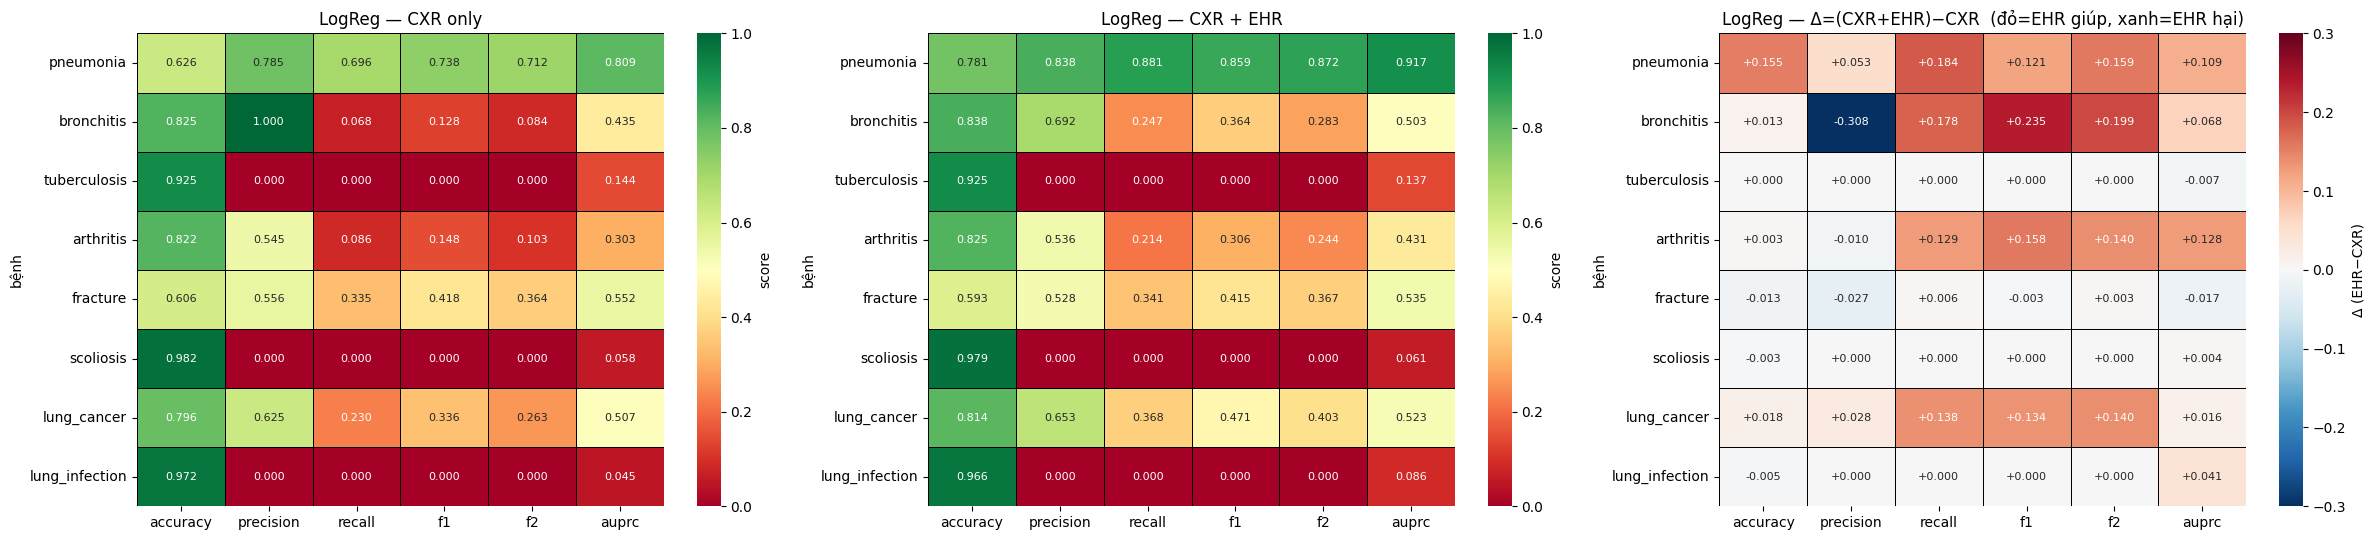

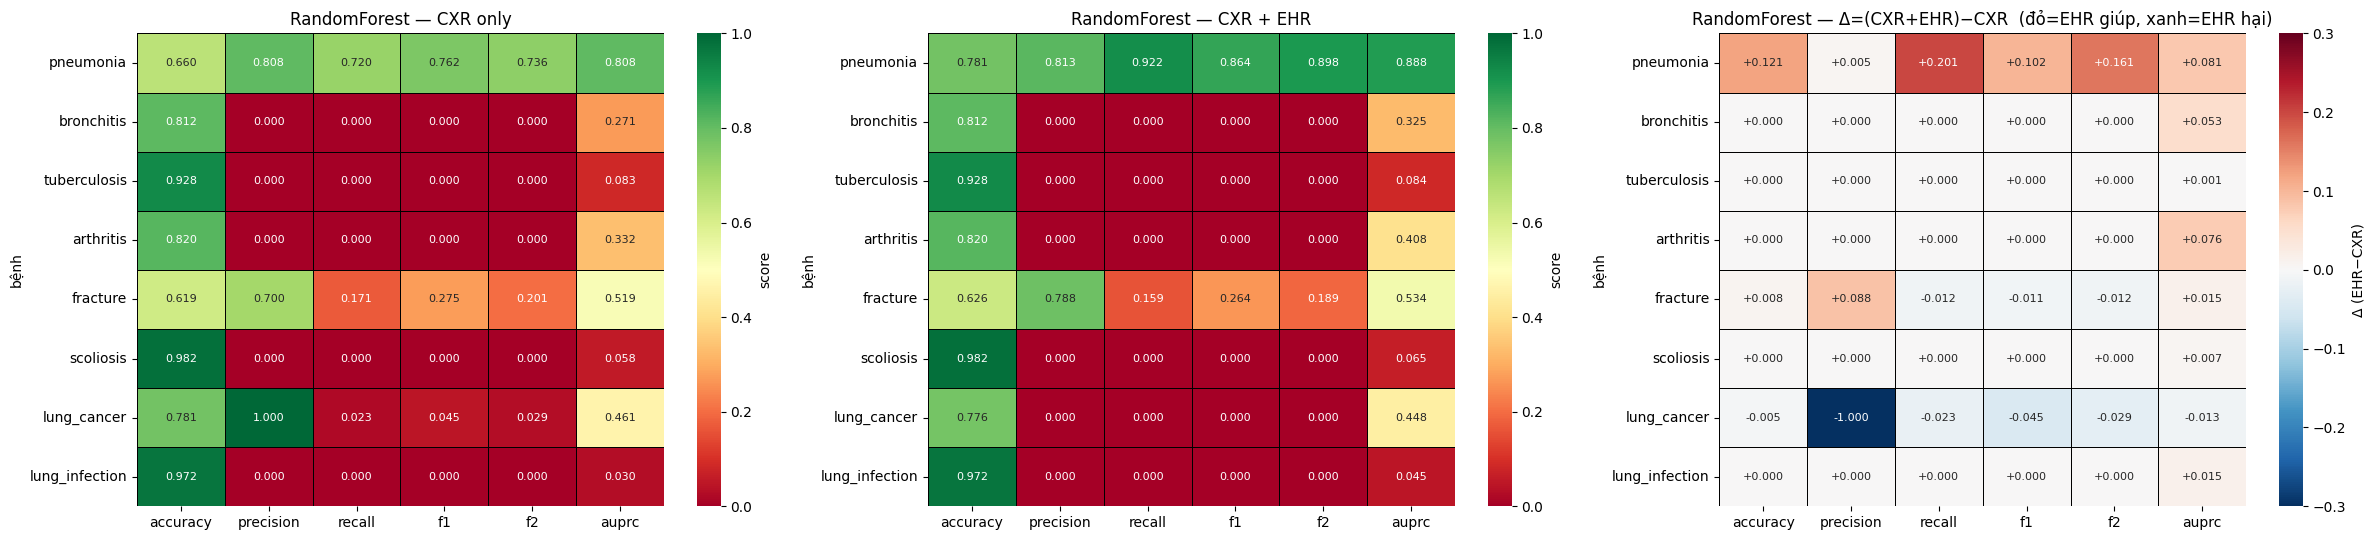

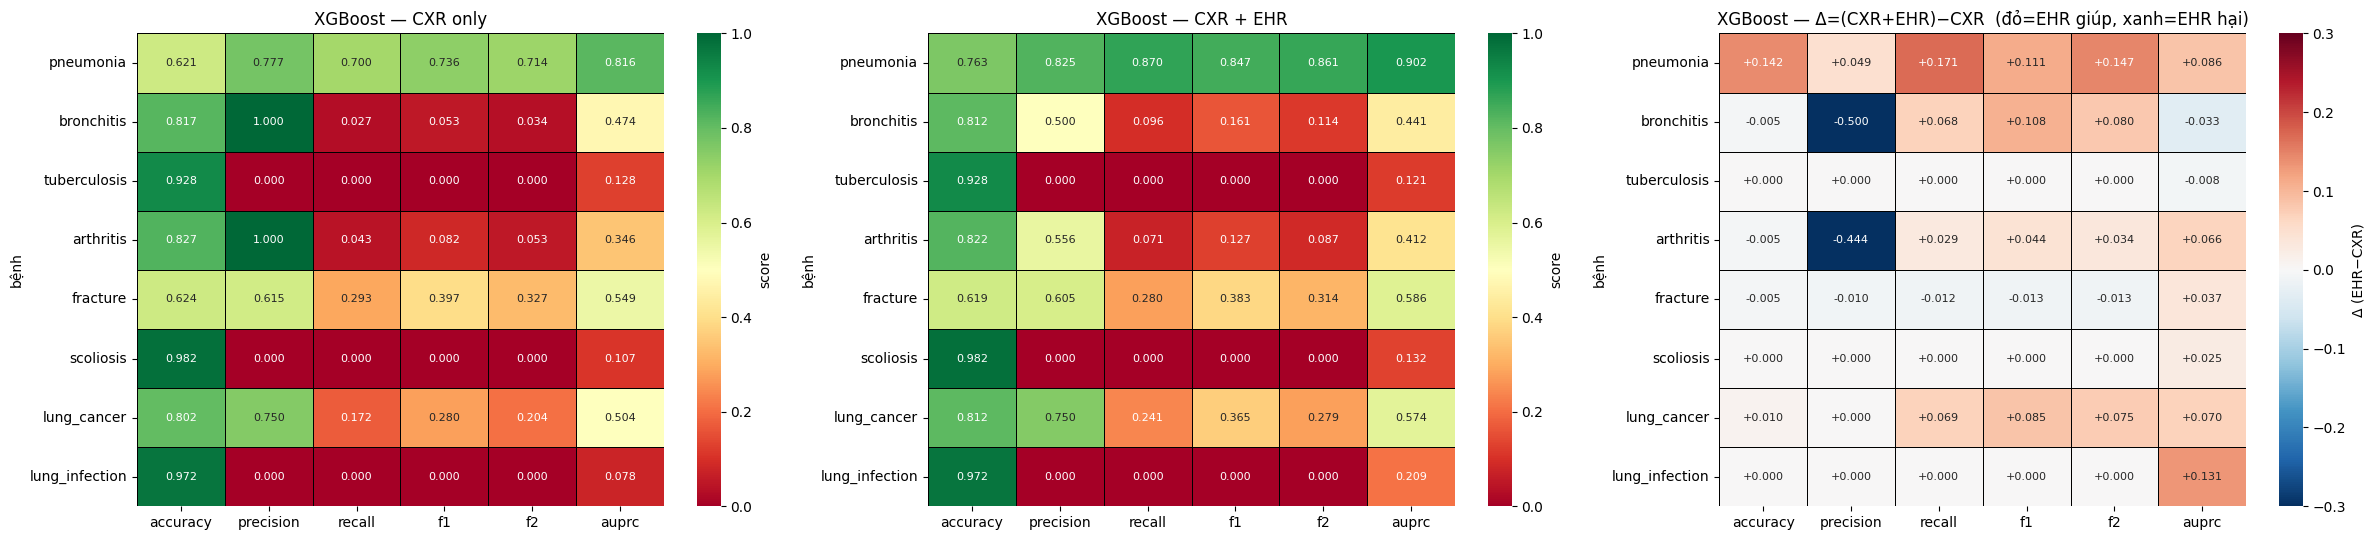

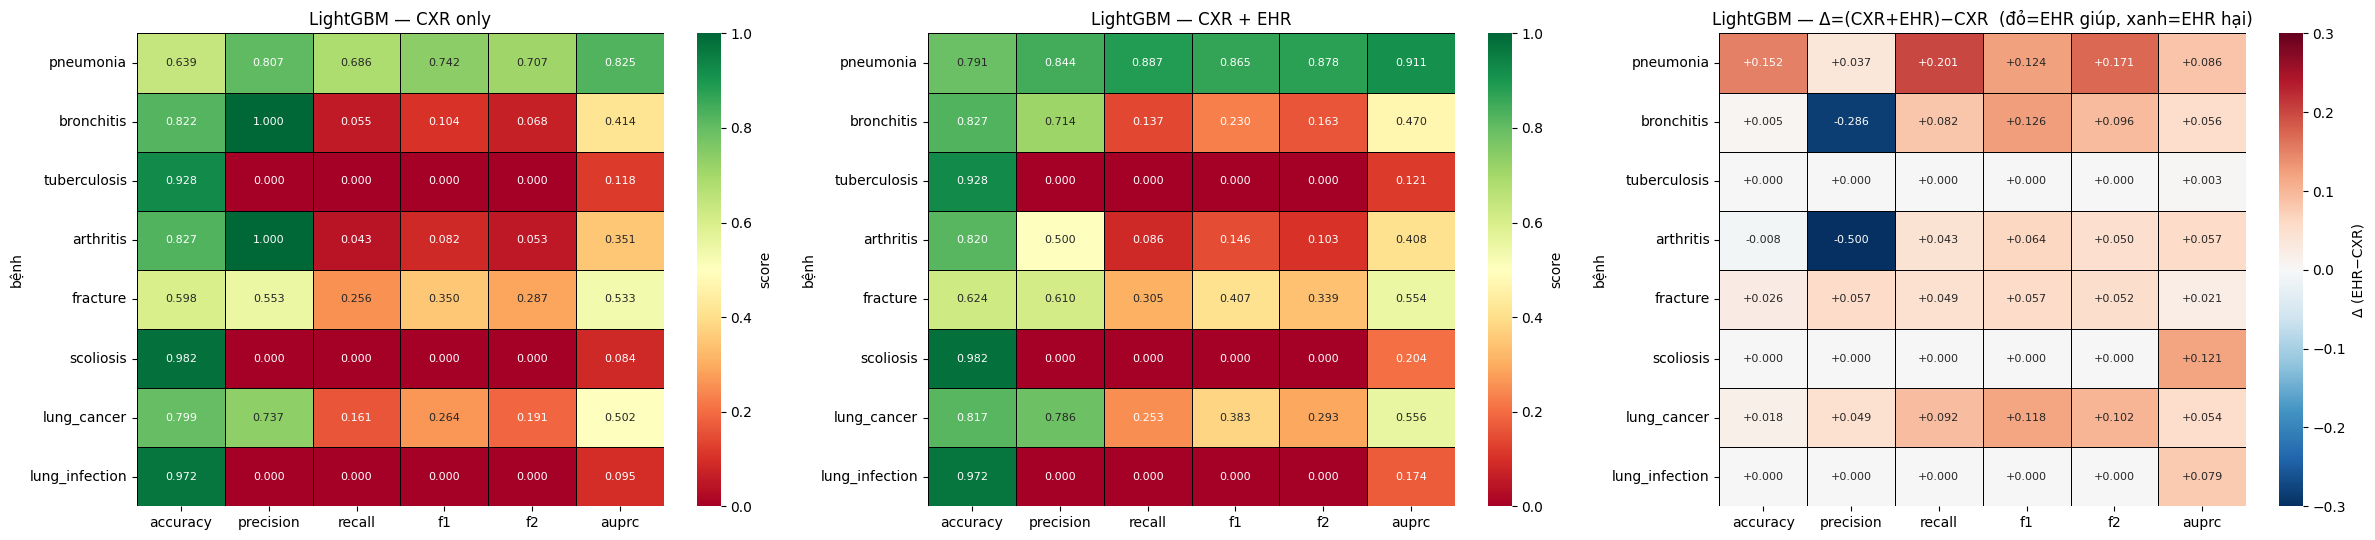

In [8]:
import matplotlib.pyplot as plt, seaborn as sns
METRICS = ['accuracy','precision','recall','f1','f2','auprc']
res = pd.read_csv(os.path.join(OUT_DIR,'benchmark_cxr_vs_ehr.csv'))

for mname in res.model.unique():
    sub = res[res.model==mname]
    A = sub[sub.featset=='CXR'].set_index('disease')[METRICS].reindex(GROUPS)
    B = sub[sub.featset=='CXR+EHR'].set_index('disease')[METRICS].reindex(GROUPS)
    D = B - A
    fig,ax = plt.subplots(1,3,figsize=(24,5.5))
    for a,M,ti in [(ax[0],A,'CXR only'),(ax[1],B,'CXR + EHR')]:
        sns.heatmap(M, ax=a, cmap='RdYlGn', vmin=0, vmax=1, annot=True, fmt='.3f',
                    linewidths=.5, linecolor='black', annot_kws={'size':8}, cbar_kws={'label':'score'})
        a.set_title(f'{mname} — {ti}')
    sns.heatmap(D, ax=ax[2], cmap='RdBu_r', center=0, vmin=-.3, vmax=.3, annot=True, fmt='+.3f',
                linewidths=.5, linecolor='black', annot_kws={'size':8}, cbar_kws={'label':'Δ (EHR−CXR)'})
    ax[2].set_title(f'{mname} — Δ=(CXR+EHR)−CXR  (đỏ=EHR giúp, xanh=EHR hại)')
    for a in ax: a.set_xlabel(''); a.set_ylabel('bệnh'); a.set_yticklabels(a.get_yticklabels(),rotation=0)
    plt.tight_layout(); plt.show()

In [ ]:
from sklearn.experimental import enable_iterative_imputer   # noqa
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, average_precision_score)
from tqdm.auto import tqdm
import numpy as np, pandas as pd, os, time, warnings
warnings.filterwarnings('ignore', message='X does not have valid feature names')

CKPT  = os.path.join(OUT_DIR,'benchmark_imputers.csv')
FRESH = False     # dataset MỚI -> True. Bị ngắt muốn chạy tiếp -> False
if FRESH and os.path.exists(CKPT):
    os.remove(CKPT); print("đã xóa checkpoint cũ -> chạy lại từ đầu")
done = set(pd.read_csv(CKPT).imputer.unique()) if os.path.exists(CKPT) else set()
if done: print("đã xong (bỏ qua):", done)

def save_block(rows_block):
    pd.DataFrame(rows_block).to_csv(CKPT, mode='a', header=not os.path.exists(CKPT), index=False)

IMPUTER_FIT_CAP = 50000
tr_idx = np.where(tr)[0]; te_idx = np.where(te)[0]
if 'TRAIN_CAP' in globals() and TRAIN_CAP and len(tr_idx)>TRAIN_CAP:
    tr_idx = np.random.default_rng(0).choice(tr_idx, TRAIN_CAP, replace=False)
fit_idx = tr_idx if not IMPUTER_FIT_CAP or len(tr_idx)<=IMPUTER_FIT_CAP \
          else np.random.default_rng(1).choice(tr_idx, IMPUTER_FIT_CAP, replace=False)

EHR_NUM = list(EHR)
Xehr   = df[EHR_NUM].apply(pd.to_numeric, errors='coerce').to_numpy('float32')
Ximg   = df[IMG].to_numpy('float32')
Ximg_s = StandardScaler().fit(Ximg[tr_idx]).transform(Ximg).astype('float32')

def build_xgb():  return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                        subsample=0.85, colsample_bytree=0.85, tree_method='hist',
                        eval_metric='logloss', n_jobs=-1, random_state=0)
def build_lgbm(): return LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                        subsample=0.85, colsample_bytree=0.85, n_jobs=-1, random_state=0, verbose=-1)
CLFS = {'XGBoost': build_xgb, 'LightGBM': build_lgbm}
IMPUTERS = {
 'MICE-default': lambda: IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=0),
 'MICE-XGB':     lambda: IterativeImputer(estimator=XGBRegressor(n_estimators=100,max_depth=3,learning_rate=0.1,
                          tree_method='hist',n_jobs=-1,random_state=0), max_iter=5, random_state=0),
 'MICE-LGBM':    lambda: IterativeImputer(estimator=LGBMRegressor(n_estimators=100,num_leaves=31,learning_rate=0.1,
                          n_jobs=-1,random_state=0,verbose=-1), max_iter=5, random_state=0),
}
def row(model, imputer, featset, g, yte, proba):
    pred=(proba>=0.5).astype(int)
    return dict(model=model, imputer=imputer, featset=featset, disease=g,
        accuracy=accuracy_score(yte,pred), precision=precision_score(yte,pred,zero_division=0),
        recall=recall_score(yte,pred,zero_division=0), f1=f1_score(yte,pred,zero_division=0),
        f2=fbeta_score(yte,pred,beta=2,zero_division=0), auprc=average_precision_score(yte,proba),
        prevalence=float(yte.mean()), n_pos_test=int(yte.sum()))
Y = {g: df[f'dx_{g}'].values.astype(int) for g in GROUPS}

def train_block(Xtr, Xte, imputer, featset):
    b=[]
    for mname, mk in CLFS.items():
        for g in tqdm(GROUPS, desc=f'{imputer:12} {mname:9}', leave=False):
            clf=mk().fit(Xtr, Y[g][tr_idx]); pr=clf.predict_proba(Xte)[:,1]
            b.append(row(mname, imputer, featset, g, Y[g][te_idx], pr))
        tqdm.write(f"   [{imputer}] {mname}: auprc={np.mean([r['auprc'] for r in b if r['model']==mname]):.3f}")
    return b

# --- baseline CXR-only ---
if '(none)' not in done:
    b = train_block(Ximg_s[tr_idx], Ximg_s[te_idx], '(none)', 'CXR')
    save_block(b); tqdm.write("✓ checkpoint: (none) CXR-only")

# --- 3 imputer x 2 clf ---
for iname, imk in tqdm(IMPUTERS.items(), desc='IMPUTERS', total=len(IMPUTERS)):
    if iname in done: tqdm.write("bỏ qua: "+iname); continue
    t0=time.time(); imp = imk().fit(Xehr[fit_idx])
    Xe = StandardScaler().fit_transform(imp.transform(Xehr).astype('float32')).astype('float32')
    Xfull = np.hstack([Ximg_s, Xe]); tqdm.write(f"[{iname}] impute+ghép {Xfull.shape} ({time.time()-t0:.0f}s)")
    b = train_block(Xfull[tr_idx], Xfull[te_idx], iname, 'CXR+EHR')
    save_block(b); tqdm.write("✓ checkpoint: "+iname); del Xfull, Xe

res_imp = pd.read_csv(CKPT)
print("\ntổng dòng:", len(res_imp), "(kỳ vọng 16 baseline + 48 = 64)")
res_imp.head()


đã xong (bỏ qua): {'(none)', 'MICE-XGB', 'MICE-default'}


IMPUTERS:   0%|          | 0/3 [00:00<?, ?it/s]

bỏ qua: MICE-default
bỏ qua: MICE-XGB


In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
METRICS = ['accuracy','precision','recall','f1','f2','auprc']
base = pd.read_csv(os.path.join(OUT_DIR,'benchmark_cxr_vs_ehr.csv'))   # CXR-only đã có
imp  = pd.read_csv(os.path.join(OUT_DIR,'benchmark_imputers.csv'))      # 6 scenario CXR+EHR

def panel(mname, kind):   # kind='CXR' -> baseline; else tên imputer
    if kind=='CXR':
        d = base[(base.model==mname)&(base.featset=='CXR')]
    else:
        d = imp[(imp.model==mname)&(imp.imputer==kind)]
    return d.set_index('disease')[METRICS].reindex(GROUPS)

PANELS = [('CXR','CXR only'),('MICE-default','CXR+EHR · MICE-default'),
          ('MICE-XGB','CXR+EHR · MICE-XGB'),('MICE-LGBM','CXR+EHR · MICE-LGBM')]
for mname in ['XGBoost','LightGBM']:
    fig,ax = plt.subplots(1,4,figsize=(30,5.5))
    for a,(kind,ti) in zip(ax,PANELS):
        sns.heatmap(panel(mname,kind), ax=a, cmap='RdYlGn', vmin=0, vmax=1, annot=True, fmt='.3f',
                    linewidths=.5, linecolor='black', annot_kws={'size':8}, cbar_kws={'label':'score'})
        a.set_title(f'{mname} — {ti}'); a.set_xlabel(''); a.set_ylabel('bệnh')
        a.set_yticklabels(a.get_yticklabels(), rotation=0)
    plt.tight_layout(); plt.show()


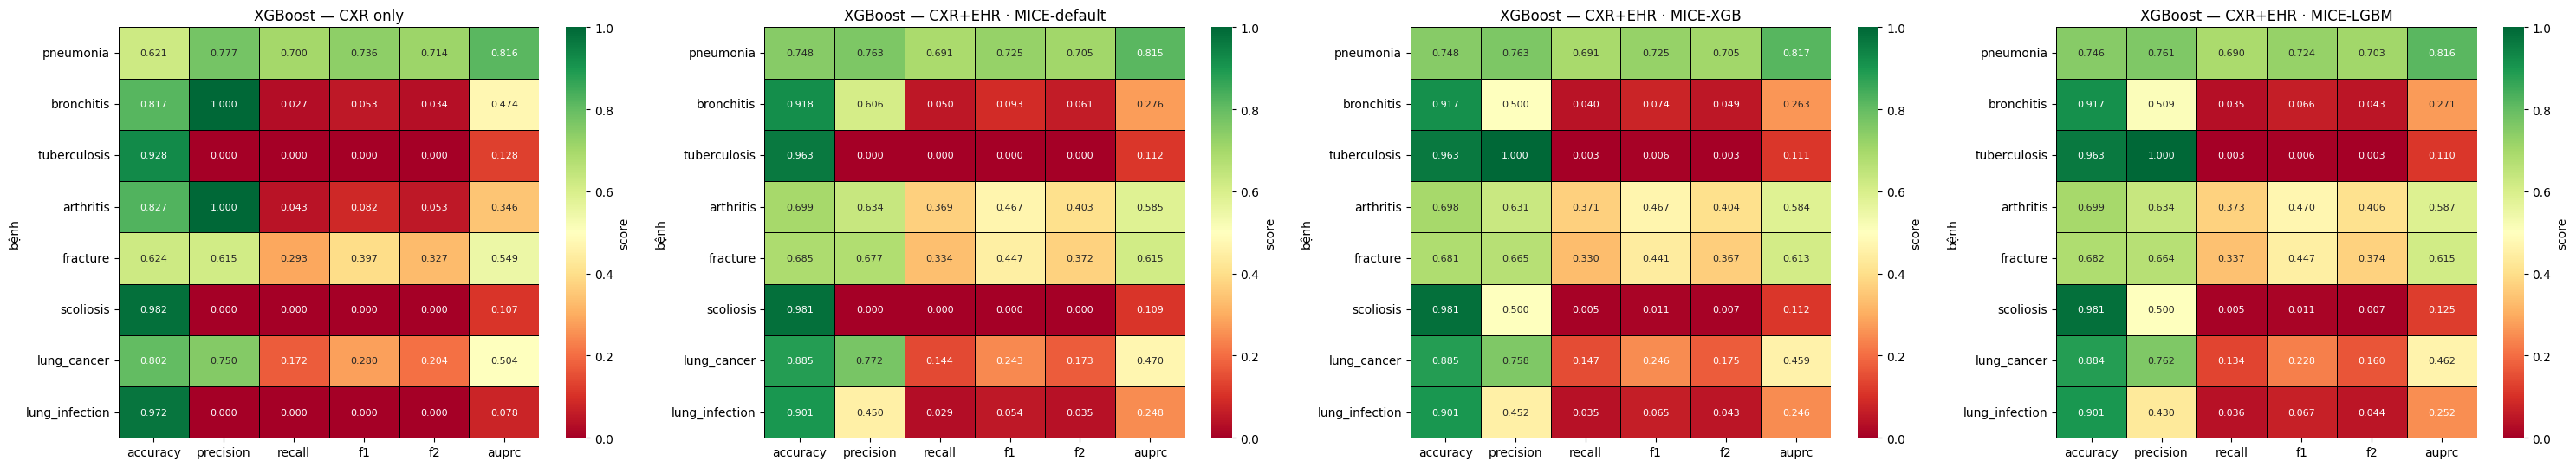

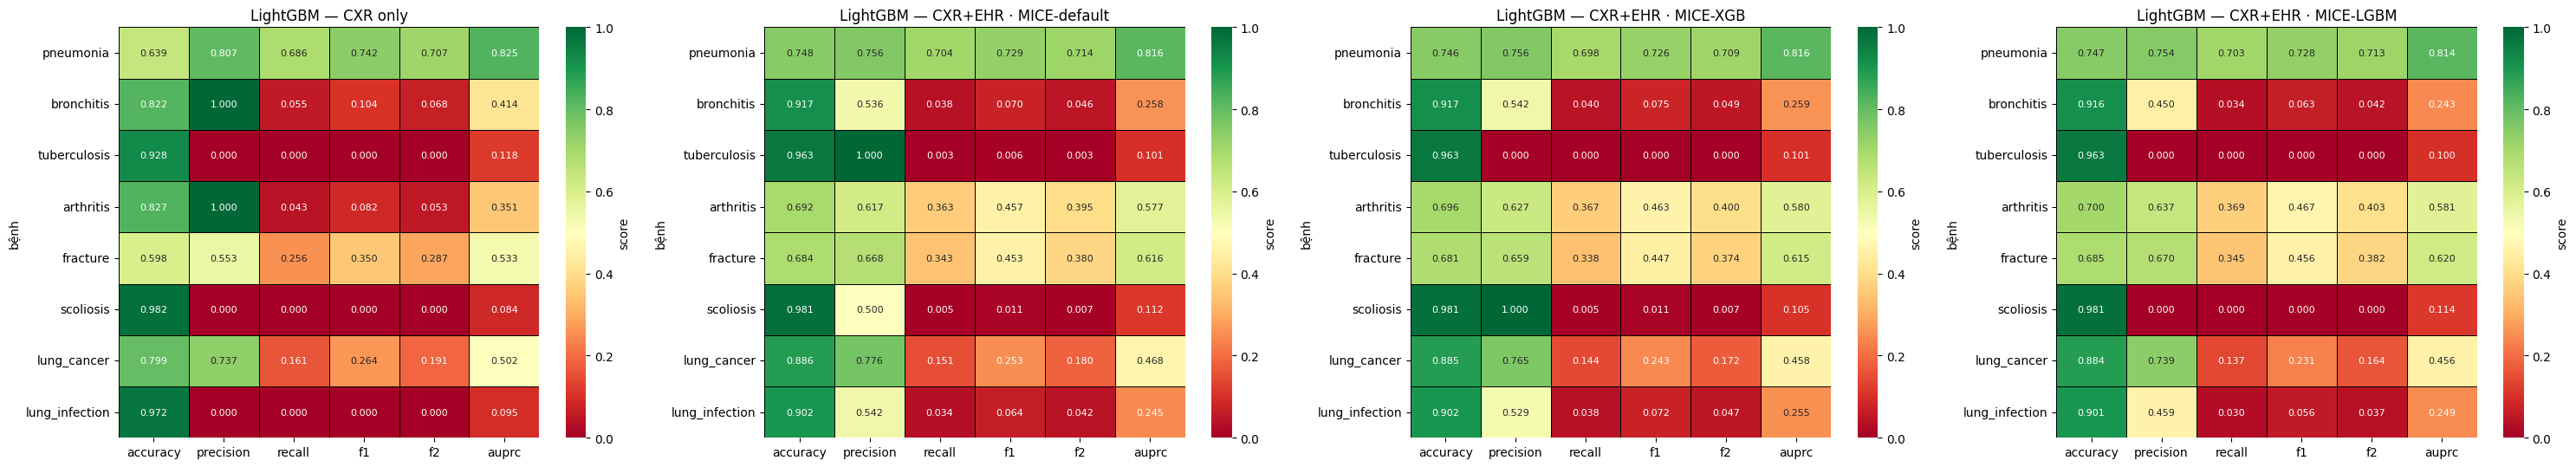

In [17]:
import matplotlib.pyplot as plt, seaborn as sns
METRICS = ['accuracy','precision','recall','f1','f2','auprc']
base = pd.read_csv(os.path.join(OUT_DIR,'benchmark_cxr_vs_ehr.csv'))   # CXR-only đã có
imp  = pd.read_csv(os.path.join(OUT_DIR,'benchmark_imputers.csv'))      # 6 scenario CXR+EHR

def panel(mname, kind):   # kind='CXR' -> baseline; else tên imputer
    if kind=='CXR':
        d = base[(base.model==mname)&(base.featset=='CXR')]
    else:
        d = imp[(imp.model==mname)&(imp.imputer==kind)]
    return d.set_index('disease')[METRICS].reindex(GROUPS)

PANELS = [('CXR','CXR only'),('MICE-default','CXR+EHR · MICE-default'),
          ('MICE-XGB','CXR+EHR · MICE-XGB'),('MICE-LGBM','CXR+EHR · MICE-LGBM')]
for mname in ['XGBoost','LightGBM']:
    fig,ax = plt.subplots(1,4,figsize=(30,5.5))
    for a,(kind,ti) in zip(ax,PANELS):
        sns.heatmap(panel(mname,kind), ax=a, cmap='RdYlGn', vmin=0, vmax=1, annot=True, fmt='.3f',
                    linewidths=.5, linecolor='black', annot_kws={'size':8}, cbar_kws={'label':'score'})
        a.set_title(f'{mname} — {ti}'); a.set_xlabel(''); a.set_ylabel('bệnh')
        a.set_yticklabels(a.get_yticklabels(), rotation=0)
    plt.tight_layout(); plt.show()


## Đọc kết quả — lưu ý
- **AUPRC vs `prevalence`**: AUPRC > prevalence nghĩa là model tốt hơn đoán mù; đây là chỉ số trung thực nhất khi mất cân bằng.
- **Recall bệnh hiếm thấp** (tuberculosis, scoliosis) ở ngưỡng 0.5 là bình thường với mô hình cơ bản không cân bằng.
- Cột **Δ** cho biết EHR **giúp bệnh nào** (thường labs/vi sinh giúp các bệnh nhiễm trùng như pneumonia/lung_infection).
- Nhãn per-patient "từng-bị" → kết quả phản ánh "dự đoán tiền sử bệnh từ ảnh + EHR", không phải chẩn đoán tức thời trên ảnh.